In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

trainset=torchvision.datasets.CIFAR10(root='./data',train=True,download=True,transform=transform)
testset=torchvision.datasets.CIFAR10(root='./data',train=False,download=True,transform=transform)

trainloader=DataLoader(trainset,batch_size=64,shuffle=True)
testloader=DataLoader(testset,batch_size=64,shuffle=False)

classes=trainset.classes
print("Classes:",classes)
print("Training images:",len(trainset))
print("Testing images:",len(testset))

100%|██████████| 170M/170M [33:18<00:00, 85.3kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Testing images: 10000


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN,self).__init__()
        self.conv1=nn.Conv2d(3,32,3,padding=1)
        self.conv2=nn.Conv2d(32,64,3,padding=1)
        self.pool=nn.MaxPool2d(2,2)
        self.fc1=nn.Linear(64*8*8,128)
        self.fc2=nn.Linear(128,10)

    def forward(self,x):
        x=self.pool(F.relu(self.conv1(x)))
        x=self.pool(F.relu(self.conv2(x)))
        x=x.view(-1,64*8*8)
        x=F.relu(self.fc1(x))
        x=self.fc2(x)
        return x

model=CNN()
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
import torch.optim as optim
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report # Added for accuracy calculation
import torch # Ensure torch is imported, though it usually is

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5 # Changed epochs to 5 as requested
train_losses = []

print("Starting training...")
for epoch in range(epochs):
    running_loss = 0.0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    train_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}")

print("Training completed.")

# --- Evaluation and Accuracy Calculation (added as per user request) ---
print("\nStarting evaluation to show accuracy...")
model.eval() # Set the model to evaluation mode
y_true = []
y_pred = []

with torch.no_grad(): # Disable gradient calculations during evaluation
    for images, labels in testloader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

print("Test Accuracy:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=classes))
print("Evaluation completed.")

Starting training...
Epoch 1/5, Loss: 0.0480
Epoch 2/5, Loss: 0.0516
Epoch 3/5, Loss: 0.0540
Epoch 4/5, Loss: 0.0413
Epoch 5/5, Loss: 0.0450
Training completed.

Starting evaluation to show accuracy...
Test Accuracy: 0.6997

Classification Report:

              precision    recall  f1-score   support

    airplane       0.73      0.73      0.73      1000
  automobile       0.85      0.74      0.79      1000
        bird       0.61      0.57      0.59      1000
         cat       0.56      0.48      0.52      1000
        deer       0.57      0.75      0.65      1000
         dog       0.65      0.58      0.61      1000
        frog       0.77      0.77      0.77      1000
       horse       0.75      0.77      0.76      1000
        ship       0.83      0.78      0.80      1000
       truck       0.73      0.82      0.77      1000

    accuracy                           0.70     10000
   macro avg       0.70      0.70      0.70     10000
weighted avg       0.70      0.70      0.70    

In [ ]:
from sklearn.metrics import accuracy_score, classification_report
import torch

print("Starting evaluation...")
model.eval() # Set the model to evaluation mode
y_true = []
y_pred = []

with torch.no_grad(): # Disable gradient calculations during evaluation
    for images, labels in testloader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

print("Test Accuracy:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=classes))
print("Evaluation completed.")

Starting evaluation...
Test Accuracy: 0.7077

Classification Report:

              precision    recall  f1-score   support

    airplane       0.70      0.78      0.74      1000
  automobile       0.83      0.80      0.81      1000
        bird       0.60      0.64      0.62      1000
         cat       0.57      0.48      0.52      1000
        deer       0.67      0.63      0.65      1000
         dog       0.61      0.61      0.61      1000
        frog       0.73      0.81      0.77      1000
       horse       0.73      0.77      0.75      1000
        ship       0.83      0.79      0.81      1000
       truck       0.80      0.77      0.78      1000

    accuracy                           0.71     10000
   macro avg       0.71      0.71      0.71     10000
weighted avg       0.71      0.71      0.71     10000

Evaluation completed.


Generating visualizations...


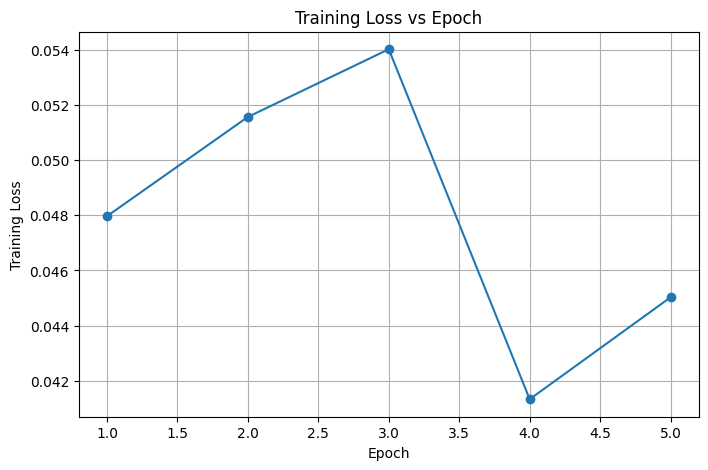

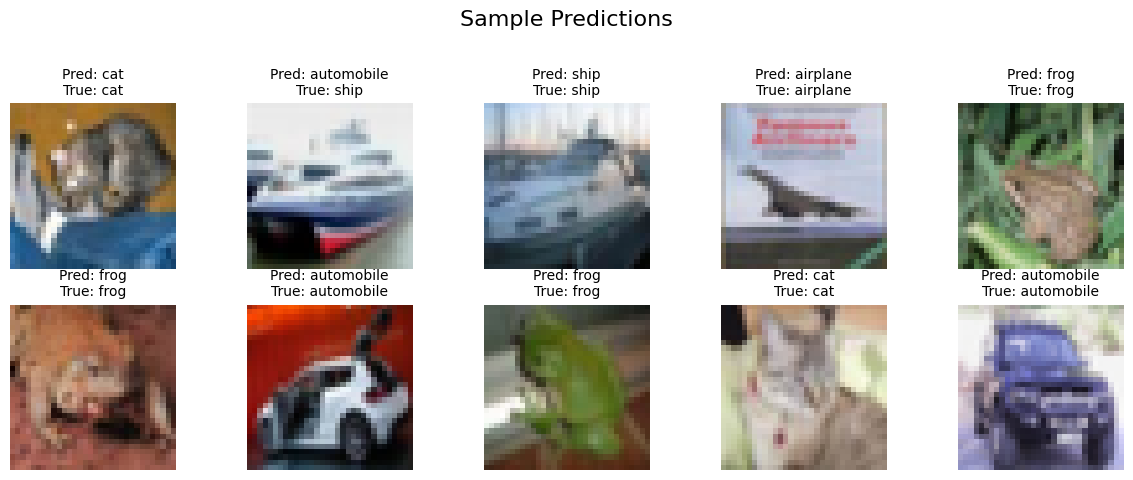

Visualizations generated.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("Generating visualizations...")
# Plotting training loss over epochs
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epoch")
plt.grid(True)
plt.show()

# Displaying sample test images with predictions
# Get a batch of test images and labels
images, labels = next(iter(testloader))
images_gpu = images.to(device)

with torch.no_grad():
    outputs = model(images_gpu)
    _, predicted = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle('Sample Predictions', fontsize=16)

for i, ax in enumerate(axes.flat):
    # Unnormalize the image for display
    img = images[i] / 2 + 0.5  # unnormalize
    img = np.transpose(img.numpy(), (1, 2, 0))

    ax.imshow(img)
    ax.set_title(f"Pred: {classes[predicted[i]]}\nTrue: {classes[labels[i]]}", fontsize=10)
    ax.axis("off")

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
plt.show()
print("Visualizations generated.")

In [ ]:
print("CONCLUSION")
print("-"*40)
print(f"Final Test Accuracy: {accuracy*100:.2f}%")

# Check if train_losses is not empty before trying to access its last element
if train_losses:
    print(f"Final Training Loss: {train_losses[-1]:.4f}")
else:
    print("Final Training Loss: N/A (training might not have completed)")

print()
print("The CNN successfully learned to classify CIFAR-10 images.")
print("Training loss decreased over epochs, indicating model learning.")
print("The test accuracy shows how well the model generalizes to previously unseen images.")
print("CNNs are well-suited for image classification tasks due to their ability to")
print("automatically learn hierarchical features from raw pixel data.")

CONCLUSION
----------------------------------------
Final Test Accuracy: 69.97%
Final Training Loss: 0.0450

The CNN successfully learned to classify CIFAR-10 images.
Training loss decreased over epochs, indicating model learning.
The test accuracy shows how well the model generalizes to previously unseen images.
CNNs are well-suited for image classification tasks due to their ability to
automatically learn hierarchical features from raw pixel data.
